# RF-DETR Nano — Smart Agriculture

RF-DETR Nano unggul pada kedua metrik submission.

Hasil nyata pada test internal: **mAP@50 72.12%**, **macro-F1 71.35%**. Notebook ini menyimpan keluaran analisis CPU dari laporan eksperimen. Sel training dan inferensi dinonaktifkan secara bawaan agar Run All tidak memulai pekerjaan GPU berjam-jam.

In [1]:
from pathlib import Path
import json
ROOT = Path.cwd()
RUN_INSTALL = False
RUN_PREPARE = False
RUN_TRAIN = False
RUN_EVALUATION = False
RUN_INFERENCE = False
DATA = ROOT / "data/coco"
WEIGHTS = ROOT / "models/RF-DETR-Nano.pth"
print("Model: RF-DETR Nano; operasi GPU dikendalikan flag eksplisit.")

Model: RF-DETR Nano; operasi GPU dikendalikan flag eksplisit.


## Data dan evaluasi

18 kelas asli dipertahankan. Data train/validation/test sama dengan baseline YOLO26s. Checkpoint dipilih dari validation mAP@50–95; confidence dari macro-F1 validation. Test hanya digunakan untuk laporan akhir percobaan ini. Benchmark internal sebelumnya telah digunakan pada eksperimen lain.

In [2]:
manifest = json.loads((ROOT / "reports/dataset_manifest.json").read_text())
for split, counts in manifest["counts"].items():
    print(split, counts)
print("Jumlah kelas:", len(manifest["categories"]))

train {'images': 8822, 'annotations': 18002, 'annotation_sha256': '864da9e170d416503f674bc7a182e8f612feb34b2be1dd1853c0e8f228b88d16'}
val {'images': 2046, 'annotations': 4758, 'annotation_sha256': 'c14e0ecce78ec31cfc262b19ba1ceed7ffea89573695470460ba64b2fb736b57'}
test {'images': 1059, 'annotations': 2669, 'annotation_sha256': '967090600c1566fd625a4ba55460d8e48ee543eff575102dad4c540bdcbf3f16'}
Jumlah kelas: 18


## Lingkungan

Python 3.11. Instal Torch/Torchvision dari indeks resmi yang sesuai dengan perangkat, lalu requirements.txt. Training ini menggunakan Torch 2.7.1 + CUDA 12.8. Gunakan RF-DETR Nano; mengganti nama bobot YOLO tidak mengubah arsitekturnya.

In [3]:
import sys, subprocess
if RUN_INSTALL:
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements.txt"], check=True)
else:
    print("Instalasi dinonaktifkan secara bawaan.")

Instalasi dinonaktifkan secara bawaan.


## Reproduksi persiapan data

Sediakan ekspor COCO asli penyelenggara di data/raw/telepati. prepare_dataset_yolo.py mengaudit dan mengurangi kebocoran dengan proksi duplikasi yang sama seperti baseline; prepare_coco.py memakai anotasi bersih loader dan menuntut hash ketiga split cocok dengan manifest. Jangan mengganti test menjadi train.

In [4]:
if RUN_PREPARE:
    subprocess.run([sys.executable, "prepare_dataset_yolo.py", "--source", "data/raw/telepati", "--output", "data/yolo", "--reports", "reports/reproduction_audit"], check=True)
    subprocess.run([sys.executable, "prepare_coco.py", "--source-yolo", "data/yolo", "--output", str(DATA)], check=True)
else:
    print("Persiapan dataset dinonaktifkan; data asli tidak disertakan.")

Persiapan dataset dinonaktifkan; data asli tidak disertakan.


## Reproduksi training

Unduh bobot awal RF-DETR Nano resmi ke models/pretrained/rf-detr-nano.pth. Bobot awal ini berbeda dari RF-DETR-Nano.pth hasil fine-tuning yang dipublikasikan. Training penuh memerlukan GPU dan beberapa jam; hasil dapat berubah menurut perangkat dan versi.

In [5]:
if RUN_TRAIN:
    subprocess.run([sys.executable, "train.py", "--data-reference", str(DATA / "dataset_reference.json"), "--pretrain", "models/pretrained/rf-detr-nano.pth", "--epochs", "12"], check=True)
else:
    print("Training dinonaktifkan secara bawaan.")

Training dinonaktifkan secara bawaan.


## Riwayat training nyata

In [6]:
training = json.loads((ROOT / "reports/training_summary.json").read_text())
print({k: training[k] for k in ["model", "completed_epochs", "best_epoch", "resolution", "batch_size", "grad_accum_steps", "seed", "checkpoint_selection"]})
for epoch in training["history"]:
    print(epoch)

{'model': 'RF-DETR Nano', 'completed_epochs': 12, 'best_epoch': 12, 'resolution': 640, 'batch_size': 8, 'grad_accum_steps': 2, 'seed': 42, 'checkpoint_selection': 'Maximum validation EMA COCO mAP@50-95; no test selection.'}
{'epoch': 1, 'metrics': {}, 'elapsed_seconds': 1037.6722114000004}
{'epoch': 2, 'metrics': {'val/mAP_50_95': 0.41999587416648865, 'val/mAP_50': 0.5763828754425049, 'val/mAP_75': 0.4373171329498291, 'val/mAR': 0.7157126069068909, 'val/ema_mAP_50_95': 0.4507168233394623, 'val/ema_mAP_50': 0.6124679446220398, 'val/ema_mAR': 0.7269986271858215, 'val/F1': 0.5496531128883362, 'val/precision': 0.5842615365982056, 'val/recall': 0.5636244416236877, 'val/AP/Bacterial panicle Blight': 0.4854746162891388, 'val/AP/False-Smut': 0.6980040669441223, 'val/AP/Healthy Rice Leaf': 0.6752449870109558, 'val/AP/Healthy Rice beads': 0.7321418523788452, 'val/AP/Infected Blast': 0.603431761264801, 'val/AP/Leaf-roller': 0.7242631912231445, 'val/AP/Blast': 0.25496459007263184, 'val/AP/BrownSpo

## Evaluasi yang dapat diulang

Buat bobot portabel terlebih dahulu dengan publish_checkpoint.py jika melatih ulang. Cache prediksi memakai bobot publik yang SHA256-nya sama dengan laporan. Scoring memakai implementasi AP/F1 yang dipin sama dengan baseline, bukan mengambil F1 tertinggi dari test.

In [7]:
if RUN_EVALUATION:
    subprocess.run([sys.executable, "cache_predictions.py", "--weights", str(WEIGHTS), "--dataset", str(DATA), "--output", "reports/predictions_reproduced"], check=True)
    subprocess.run([sys.executable, "score.py", "--dataset", str(DATA), "--cache", "reports/predictions_reproduced", "--baseline", "reports/baseline_yolo26s.json", "--output", "reports/evaluation_reproduced"], check=True)
else:
    print("Evaluasi GPU dinonaktifkan secara bawaan.")

Evaluasi GPU dinonaktifkan secara bawaan.


## Hasil submission dan perbandingan

In [8]:
metrics = json.loads((ROOT / "reports/evaluation/metrics.json").read_text())
for split in ["val", "test"]:
    print(split, {key: round(metrics[split][key] * 100, 4) for key in ["mAP50", "mAP50_95", "macro_f1_iou50"]})
print("Confidence dari validation:", metrics["selected_confidence"])
print("Perbandingan:", metrics["comparison"])

val {'mAP50': 70.7367, 'mAP50_95': 51.4973, 'macro_f1_iou50': 70.5022}
test {'mAP50': 72.1243, 'mAP50_95': 55.4319, 'macro_f1_iou50': 71.3519}
Confidence dari validation: 0.3943943943943944
Perbandingan: {'baseline': 'YOLO26s', 'baseline_weights_sha256': '2b4a698f807590bea2a8f91bcd9d7b54b52f3b48d76640a421fb9fb9398d959b', 'baseline_test': {'mAP50': 0.6679665908318583, 'mAP50_95': 0.4725391269453685, 'macro_precision_iou50': 0.6901023053061981, 'macro_recall_iou50': 0.7111576623745786, 'macro_f1_iou50': 0.673120427394553, 'gt_instances': 2669, 'classes_evaluated': 18, 'speed_ms_per_image': {'preprocess': 1.095378186967024, 'inference': 8.456977242680574, 'loss': 0.0020233238863097405, 'postprocess': 1.418426251195696}}, 'mAP50_delta_percentage_points': 5.32761068244506, 'macro_f1_delta_percentage_points': 4.039871781526738, 'both_submission_metrics_better': True, 'different_inference_preprocessing': 'RF-DETR square resize; YOLO default letterbox.', 'uncertainty': 'Single-seed experiment;

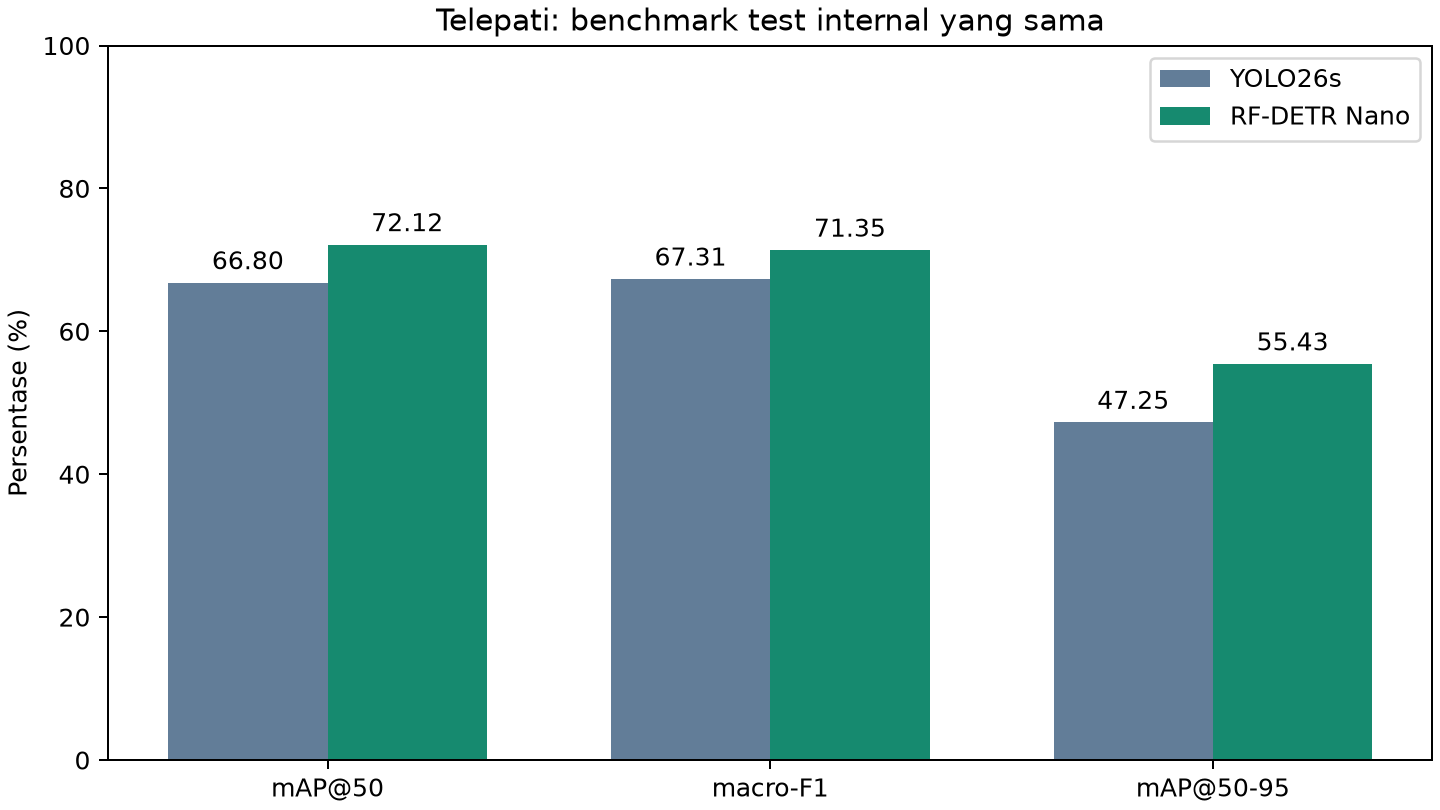

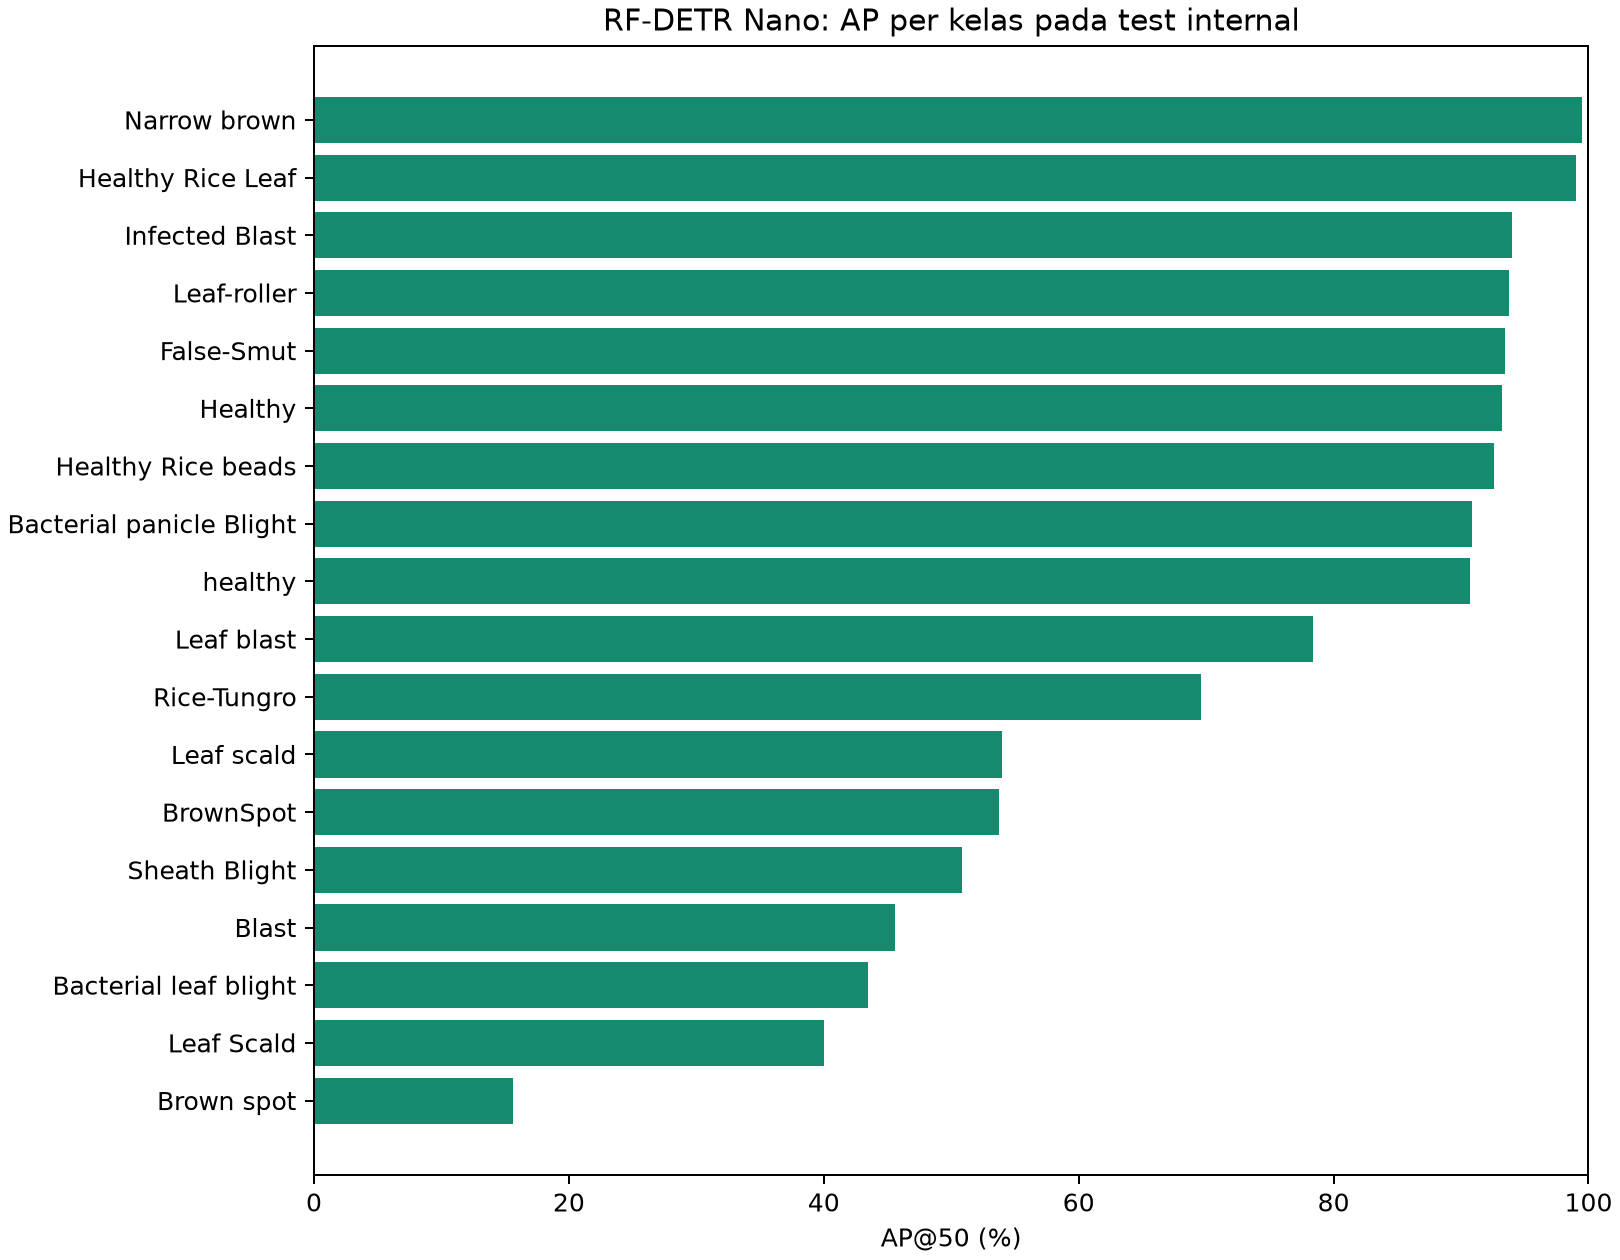

In [9]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "reports/figures/comparison.png")))
display(Image(filename=str(ROOT / "reports/figures/per_class_ap.png")))

## AP per kelas dan confusion matrix

Confusion matrix di bawah menggunakan confidence dari validation dan IoU pencocokan 0,50; baris adalah prediksi, kolom adalah kelas aktual. Background bukan kelas tanaman. Precision/recall interpolasi untuk F1 dapat berbeda dari rasio hitungan matrix karena definisi pencocokan dan interpolasi.

Brown spot AP50 15.59 F1 17.94
Leaf Scald AP50 40.0 F1 47.07
Bacterial leaf blight AP50 43.47 F1 54.03
Blast AP50 45.61 F1 48.75
Sheath Blight AP50 50.84 F1 53.32
BrownSpot AP50 53.74 F1 59.6
Leaf scald AP50 53.99 F1 61.69
Rice-Tungro AP50 69.6 F1 69.44
Leaf blast AP50 78.4 F1 73.49
healthy AP50 90.72 F1 83.77
Bacterial panicle Blight AP50 90.82 F1 80.97
Healthy Rice beads AP50 92.59 F1 94.69
Healthy AP50 93.19 F1 90.58
False-Smut AP50 93.45 F1 88.9
Leaf-roller AP50 93.72 F1 81.34
Infected Blast AP50 93.97 F1 83.82
Healthy Rice Leaf AP50 99.04 F1 96.07
Narrow brown AP50 99.5 F1 98.86


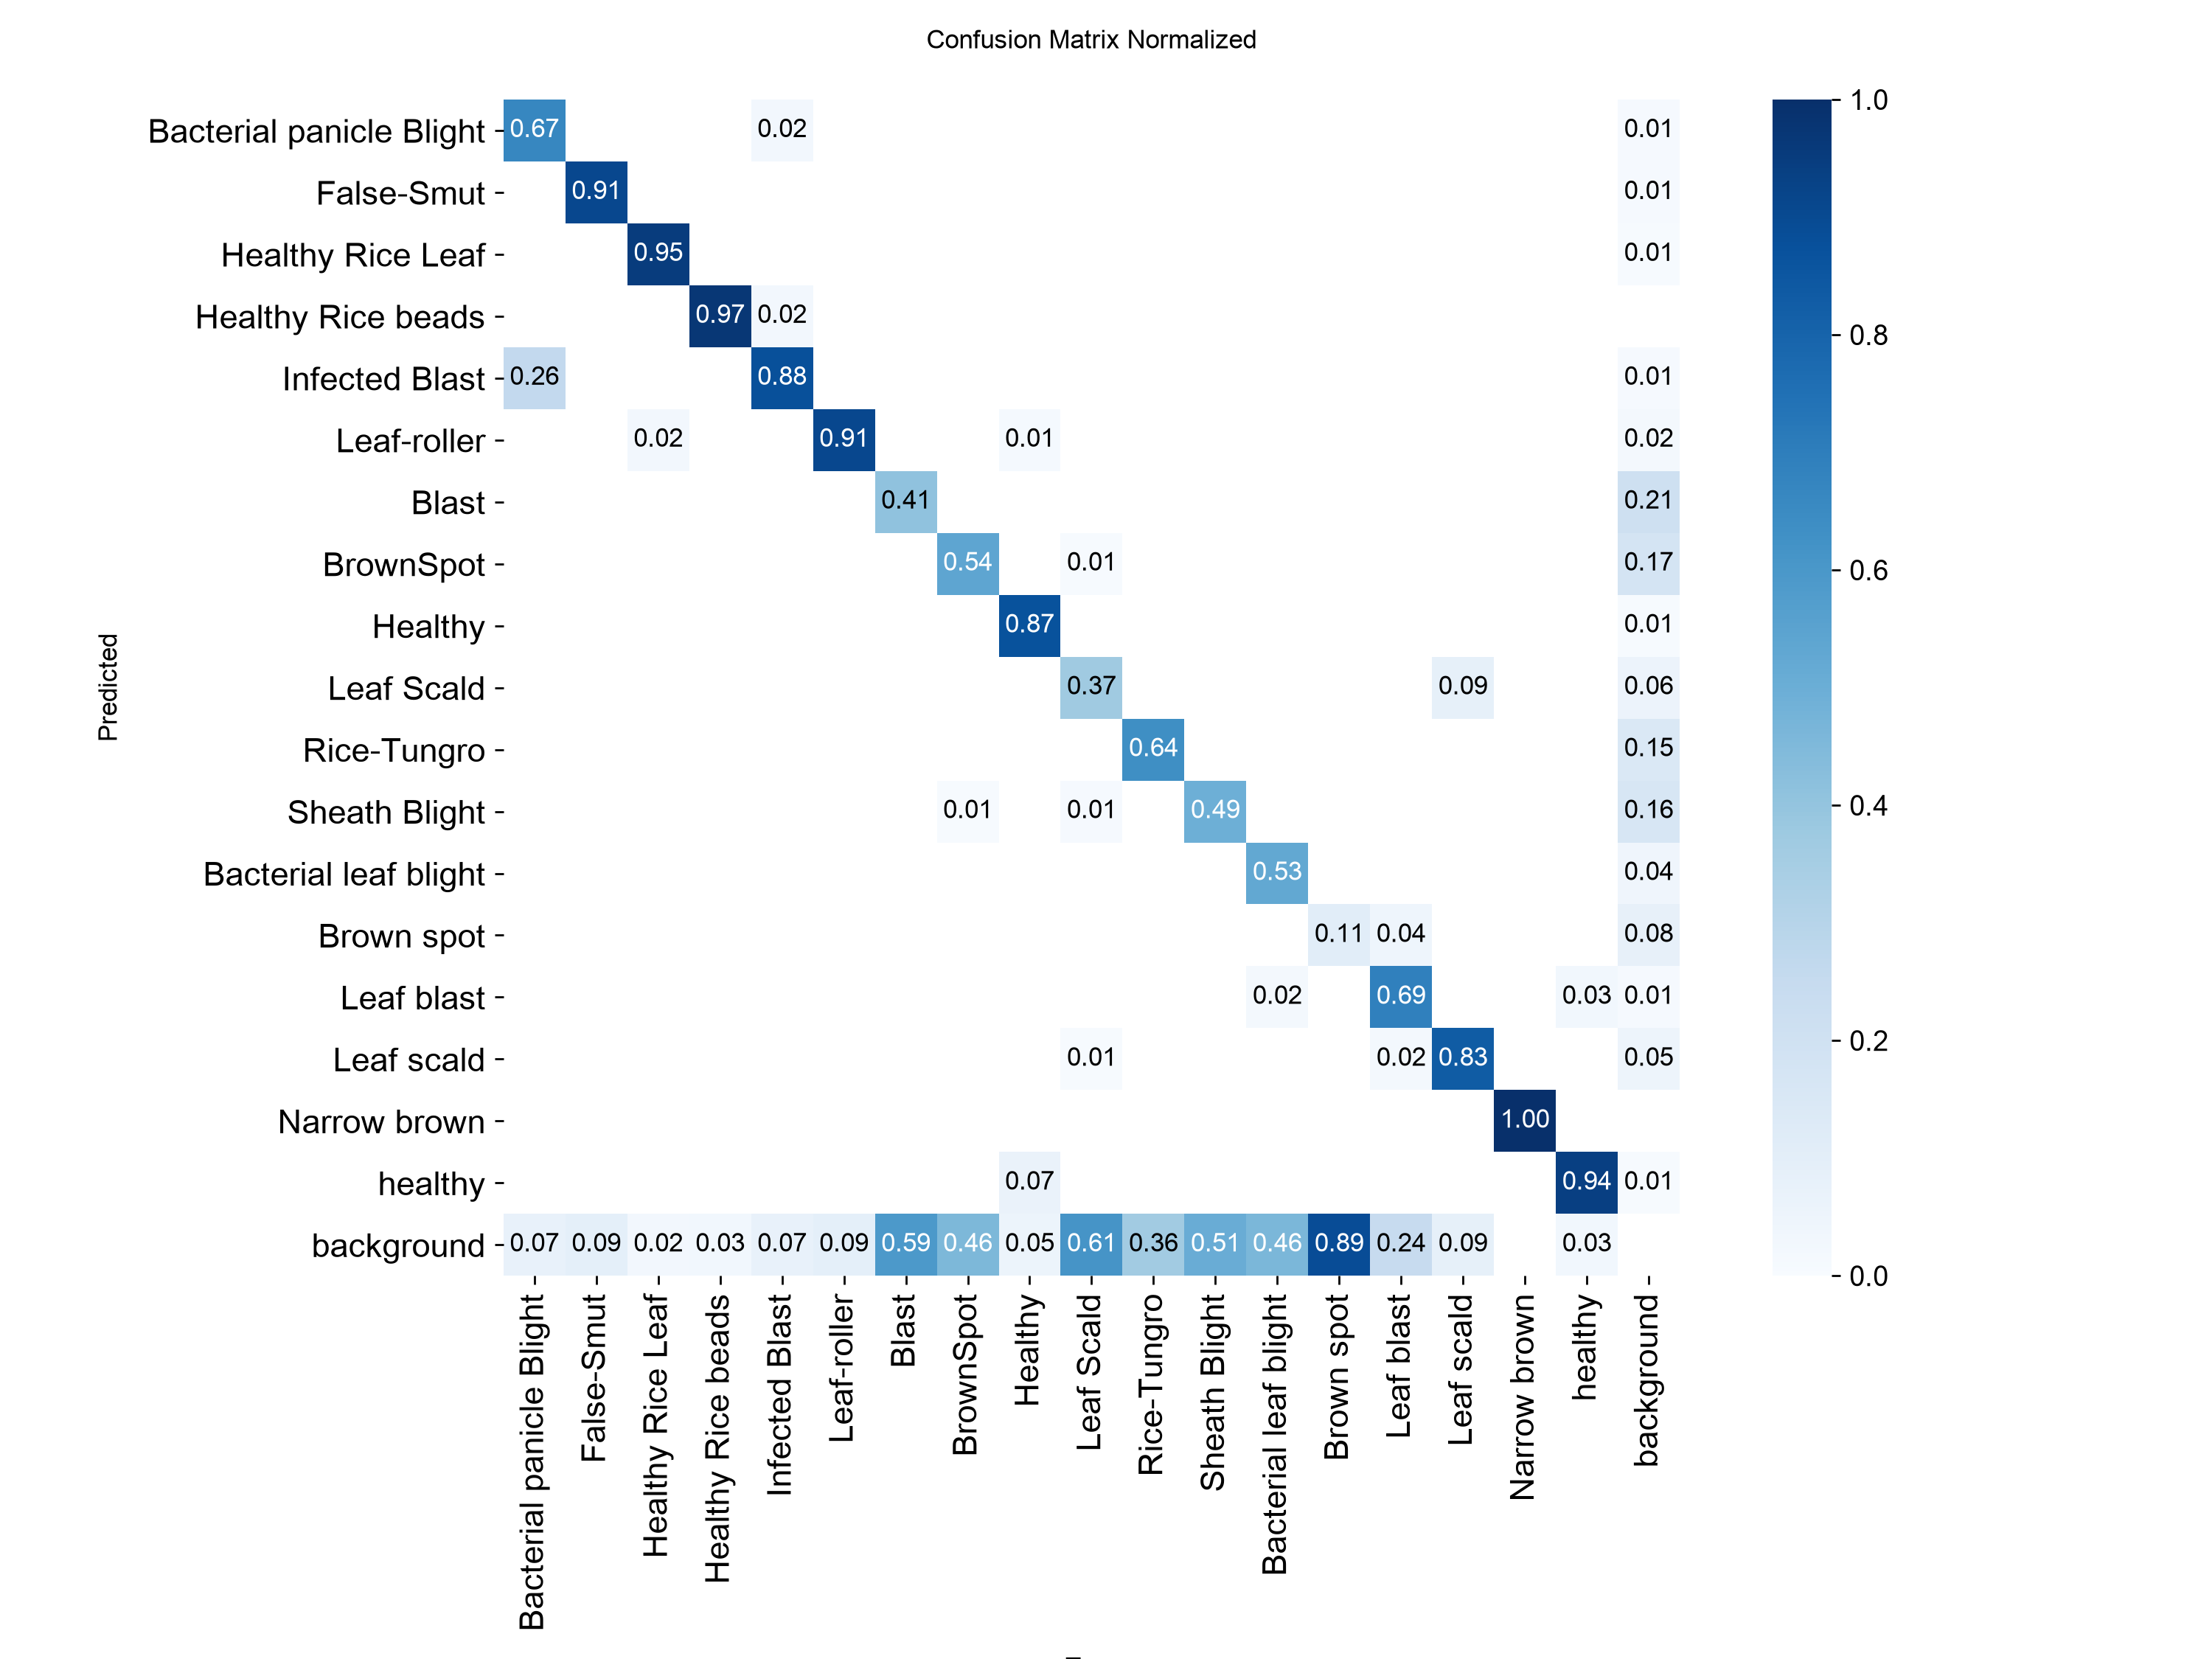

In [10]:
import csv
with (ROOT / "reports/evaluation/per_class_metrics.csv").open(encoding="utf-8-sig") as handle:
    rows = [r for r in csv.DictReader(handle) if r["split"] == "test"]
for row in sorted(rows, key=lambda r: float(r["ap50"])):
    print(row["class_name"], "AP50", round(float(row["ap50"]) * 100, 2), "F1", round(float(row["f1_iou50"]) * 100, 2))
display(Image(filename=str(ROOT / "reports/evaluation/test/confusion_matrix_normalized.png")))

## Inferensi gambar sendiri

In [11]:
if RUN_INFERENCE:
    from rfdetr import RFDETRNano
    model = RFDETRNano(pretrain_weights=str(WEIGHTS), num_classes=18, resolution=640, positional_encoding_size=40)
    detections = model.predict(str(ROOT / "examples/input.jpg"), threshold=metrics["selected_confidence"])
    print(detections)
else:
    print("Inferensi dinonaktifkan. Sediakan gambar sendiri dan aktifkan RUN_INFERENCE.")

Inferensi dinonaktifkan. Sediakan gambar sendiri dan aktifkan RUN_INFERENCE.


## Integritas dan batas penggunaan

Hasil ini merupakan evaluasi object detection pada gambar benchmark internal, belum membuktikan diagnosis agronomi atau kinerja kamera drone. Jangan menyamakan confidence dengan probabilitas terkalibrasi. Periksa kelas lemah dan label yang mirip pada MODEL_CARD.md serta laporan per kelas. [RF-DETR resmi](https://github.com/roboflow/rf-detr); [panduan training](https://rfdetr.roboflow.com/learn/train/).

In [12]:
provenance = json.loads((ROOT / "reports/public_checkpoint.json").read_text())
print("SHA256:", provenance["weights_sha256"])
print("Seluruh tensor tidak berubah:", provenance["all_model_tensors_identical"])

SHA256: 16986ca5759c80869dd46fe121efd1ae434a98a1831dc8bf86d27b6dacb38338
Seluruh tensor tidak berubah: True
